# MNIST Handwritten Digit Classification

## Project overview
Explore handwritten digit images (28×28 pixels) and train classifiers to recognize digits. The notebook covers binary classification (digit 5 vs. not 5), model evaluation, multiclass classification, error analysis, and image-shift/data-augmentation experiments.

## Tools
Python, pandas, NumPy, Matplotlib, SciPy, and scikit-learn.

## Dataset
This notebook uses the **Digit Recognizer** training CSV from Kaggle. Download `train.csv` and update the data path in the loading cell. The CSV has a `label` column and 784 pixel columns.

## How to run
1. Install packages from `requirements.txt`.
2. Download `train.csv` from Kaggle.
3. Set `DATA_PATH` in the loading cell to the CSV location.
4. Run all cells from top to bottom. Some SVM, cross-validation, and augmentation cells can take several minutes.

The dataset's provided training CSV contains 42,000 rows, so this notebook creates its train/test split with `train_test_split` rather than assuming 60,000 rows.


In [9]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input director
import os
for dirname, _, filenames in os.walk('/kaggle/input/digit_recognizer'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# LOADING MNIST DATA SET 

In [13]:
from pathlib import Path

# Set this to the location of the downloaded Kaggle train.csv file.
DATA_PATH = Path("data/train.csv")
if not DATA_PATH.exists():
    kaggle_path = Path("/kaggle/input/digit-recognizer/train.csv")
    if kaggle_path.exists():
        DATA_PATH = kaggle_path
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find train.csv at {DATA_PATH}. Download the Kaggle Digit Recognizer data "
        "and update DATA_PATH to the correct location."
    )
df = pd.read_csv(DATA_PATH)
print("Loaded dataset:", df.shape)
display(df.head())

In [14]:
X = df.drop("label", axis=1).values
y = df["label"].values

In [22]:
X.shape

(42000, 784)

In [16]:
y.shape

(42000,)

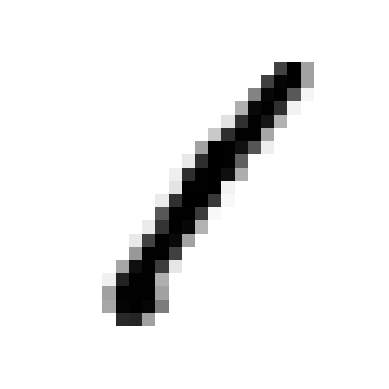

Label: 1


In [23]:
import matplotlib.pyplot as plt

def plot_digit(image_data):
    image = image_data.reshape(28, 28)
    plt.imshow(image, cmap="binary")
    plt.axis("off")

some_digit = X[0]
plot_digit(some_digit)
plt.savefig("some_digit_plot.png", bbox_inches="tight")
plt.show()
print("Label:", y[0])


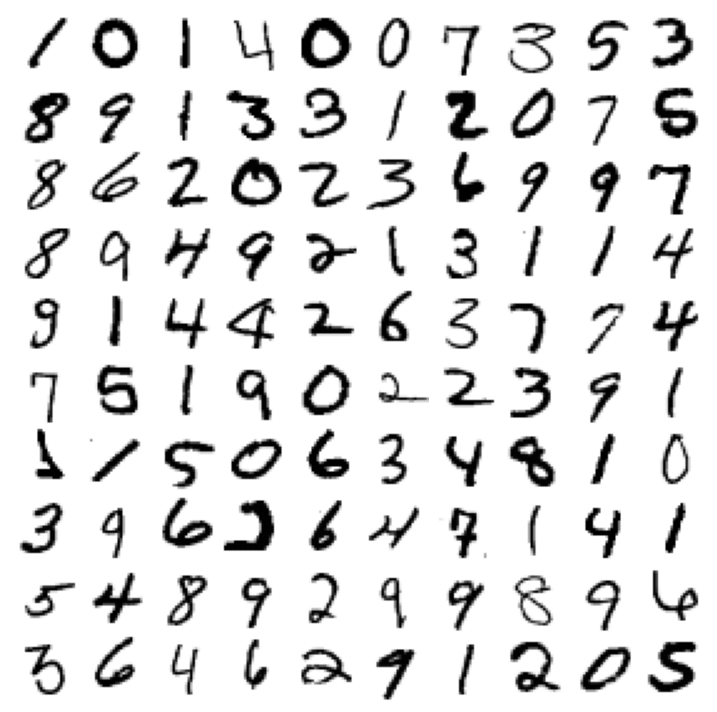

In [11]:
X = df.drop("label", axis=1).values
y = df["label"].values

def plot_digit(image_data):
    image = image_data.reshape(28, 28)
    plt.imshow(image, cmap="binary")
    plt.axis("off")
plt.figure(figsize=(9, 9))

for idx, image_data in enumerate(X[:100]):
    plt.subplot(10, 10, idx + 1)
    plot_digit(image_data)

plt.subplots_adjust(wspace=0, hspace=0)
plt.savefig("more_digits_plot.png", bbox_inches="tight")
plt.show()


In [12]:
# Use a reproducible holdout split; the Kaggle training CSV has 42,000 rows.
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [13]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import SGDClassifier
from sklearn.dummy import DummyClassifier
X = df.drop("label", axis=1).values.astype(float)
y = df["label"].values.astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
y_train_5 = (y_train == 5)
y_test_5 = (y_test == 5)
sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train_5)
print("Prediction for first X_test:", sgd_clf.predict([X_test[0]]))
print("Actual label:", y_test[0], "Is 5?", y_test_5[0])
some_digit = X[0]
print("Prediction for some_digit:", sgd_clf.predict([some_digit]))
dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_scores = cross_val_score(dummy_clf, X_train, y_train_5, cv=3, scoring="accuracy")
print("Dummy classifier accuracy:", dummy_scores.mean())


Prediction for first X_test: [False]
Actual label: 8 Is 5? False
Prediction for some_digit: [False]
Dummy classifier accuracy: 0.9079464285714286


In [31]:
X = df.drop("label", axis=1).values.astype(float)
y = df["label"].values.astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
y_train_5 = (y_train == 5)
y_test_5 = (y_test == 5)
sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train_5)
accuracy_scores = cross_val_score(sgd_clf, X_train, y_train_5, cv=3, scoring="accuracy")
print("Cross-validation accuracy scores:", accuracy_scores)
print("Mean accuracy:", accuracy_scores.mean())


Cross-validation accuracy scores: [0.94526786 0.95776786 0.96625   ]
Mean accuracy: 0.9564285714285714


In [32]:
from sklearn.dummy import DummyClassifier

dummy_clf = DummyClassifier()
dummy_clf.fit(X_train, y_train_5)
print(any(dummy_clf.predict(X_train)))

False


In [33]:
cross_val_score(dummy_clf, X_train, y_train_5, cv=3, scoring="accuracy")

array([0.90794643, 0.90794643, 0.90794643])

# Performance Measures

# Multiclass Classification

In [34]:
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import confusion_matrix
X = df.drop("label", axis=1).values.astype(float)
y = df["label"].values.astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

y_train_5 = (y_train == 5)
sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train_5)
y_train_pred = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3)
cm = confusion_matrix(y_train_5, y_train_pred)
cm

array([[29810,   697],
       [  767,  2326]])

In [35]:
y_train_perfect_predictions = y_train_5 
confusion_matrix(y_train_5, y_train_perfect_predictions)

array([[30507,     0],
       [    0,  3093]])

In [36]:
from sklearn.metrics import precision_score, recall_score

precision_score(y_train_5, y_train_pred)

0.7694343367515712

In [37]:
cm[1, 1] / (cm[0, 1] + cm[1, 1])

np.float64(0.7694343367515712)

In [38]:
recall_score(y_train_5, y_train_pred)

0.7520206918849014

In [39]:
cm[1, 1] / (cm[1, 0] + cm[1, 1])

np.float64(0.7520206918849014)

In [40]:
from sklearn.metrics import f1_score

f1_score(y_train_5, y_train_pred)
cm[1, 1] / (cm[1, 1] + (cm[1, 0] + cm[0, 1]) / 2)

np.float64(0.7606278613472858)

In [47]:
y_scores = sgd_clf.decision_function([some_digit])
y_scores
threshold = 0

In [48]:
y_some_digit_pred = (y_scores > threshold)
y_some_digit_pred
threshold = 3000
y_some_digit_pred = (y_scores > threshold)
y_some_digit_pred

array([False])

In [49]:
y_scores = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3,
                             method="decision_function")

In [50]:
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_train_5, y_scores)

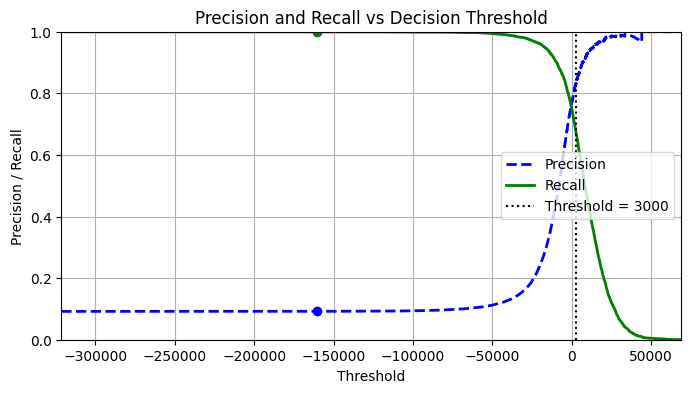

In [51]:
plt.figure(figsize=(8, 4))
plt.plot(thresholds, precisions[:-1], "b--", label="Precision", linewidth=2)
plt.plot(thresholds, recalls[:-1], "g-", label="Recall", linewidth=2)
plt.axvline(x=threshold, color="k", linestyle="dotted", label=f"Threshold = {threshold}")
plt.plot(thresholds[idx], precisions[idx], "bo")
plt.plot(thresholds[idx], recalls[idx], "go")

plt.axis([thresholds.min(), thresholds.max(), 0, 1])
plt.grid(True)
plt.xlabel("Threshold")
plt.ylabel("Precision / Recall")
plt.title("Precision and Recall vs Decision Threshold")
plt.legend(loc="center right")
plt.show()

In [53]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from sklearn.metrics import precision_recall_curve

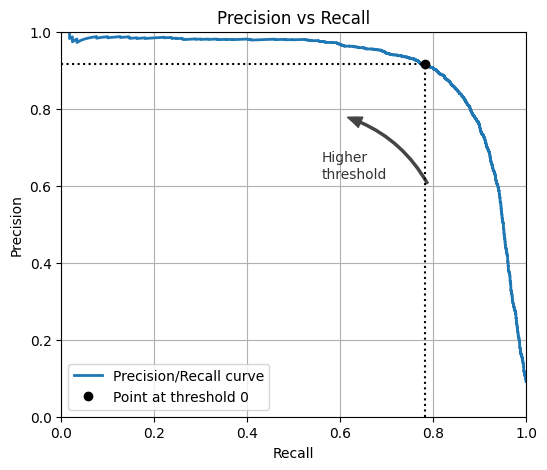

In [54]:
y_scores = sgd_clf.decision_function(X_train)
precisions, recalls, thresholds = precision_recall_curve(y_train_5, y_scores)
threshold = 0  # change this to any threshold
idx = (thresholds >= threshold).argmax()  # first index >= threshold
plt.figure(figsize=(6, 5))
plt.plot(recalls, precisions, linewidth=2, label="Precision/Recall curve")
plt.plot([recalls[idx], recalls[idx]], [0., precisions[idx]], "k:")
plt.plot([0.0, recalls[idx]], [precisions[idx], precisions[idx]], "k:")
plt.plot([recalls[idx]], [precisions[idx]], "ko",
         label=f"Point at threshold {threshold}")
plt.gca().add_patch(patches.FancyArrowPatch(
    (0.79, 0.60), (0.61, 0.78),
    connectionstyle="arc3,rad=.2",
    arrowstyle="Simple, tail_width=1.5, head_width=8, head_length=10",
    color="#444444"))
plt.text(0.56, 0.62, "Higher\nthreshold", color="#333333")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.axis([0, 1, 0, 1])
plt.grid(True)
plt.legend(loc="lower left")
plt.title("Precision vs Recall")
plt.savefig("precision_vs_recall_plot.png", bbox_inches="tight")

plt.show()


In [55]:
idx_for_90_precision = (precisions >= 0.90).argmax()
threshold_for_90_precision = thresholds[idx_for_90_precision]
threshold_for_90_precision

np.float64(-517.9552426932589)

In [56]:
y_train_pred_90 = (y_scores >= threshold_for_90_precision)
precision_score(y_train_5, y_train_pred_90)
recall_at_90_precision = recall_score(y_train_5, y_train_pred_90)
recall_at_90_precision

0.8060135790494666

# ROC Curve

In [58]:
from sklearn.metrics import roc_curve
fpr, tpr, thresholds = roc_curve(y_train_5, y_scores)

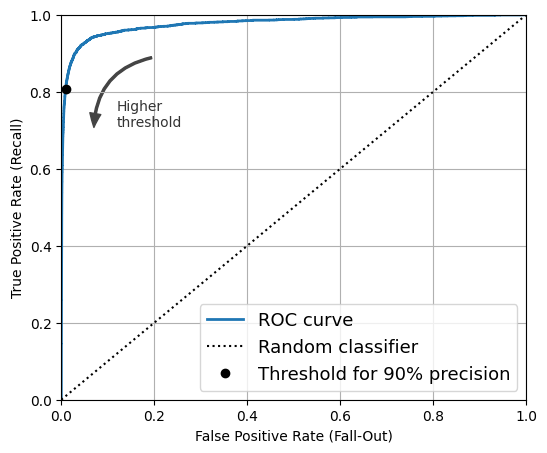

In [59]:
y_scores = sgd_clf.decision_function(X_train)
fpr, tpr, thresholds = roc_curve(y_train_5, y_scores)
idx_for_threshold_at_90 = (thresholds <= threshold_for_90_precision).argmax()
tpr_90 = tpr[idx_for_threshold_at_90]
fpr_90 = fpr[idx_for_threshold_at_90]
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, linewidth=2, label="ROC curve")
plt.plot([0, 1], [0, 1], "k:", label="Random classifier")
plt.plot(fpr_90, tpr_90, "ko", label="Threshold for 90% precision")
plt.gca().add_patch(
    patches.FancyArrowPatch(
        (0.20, 0.89), (0.07, 0.70),
        connectionstyle="arc3,rad=.4",
        arrowstyle="Simple, tail_width=1.5, head_width=8, head_length=10",
        color="#444444"
    )
)

plt.text(0.12, 0.71, "Higher\nthreshold", color="#333333")
plt.xlabel("False Positive Rate (Fall-Out)")
plt.ylabel("True Positive Rate (Recall)")
plt.axis([0, 1, 0, 1])
plt.grid(True)
plt.legend(loc="lower right", fontsize=13)
plt.savefig("roc_curve_plot.png", bbox_inches="tight")
plt.show()


In [60]:
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict

roc_auc = roc_auc_score(y_train_5, y_scores)
roc_auc


np.float64(0.9773363617521499)

In [64]:
forest_clf = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    n_jobs=-1
)

In [65]:
y_probas_forest = cross_val_predict(
    forest_clf,
    X_train,
    y_train_5,
    cv=3,
    method="predict_proba"
)
y_probas_forest[:2]


array([[0.99, 0.01],
       [0.02, 0.98]])

In [66]:
proba_5 = y_probas_forest[:, 1]
mask_50_to_60 = (proba_5 > 0.50) & (proba_5 < 0.60)
if mask_50_to_60.sum() > 0:
    percent_5s = y_train_5[mask_50_to_60].mean()
else:
    percent_5s = 0.0

print(f"{percent_5s:.1%}")
precisions_forest, recalls_forest, thresholds_forest = precision_recall_curve(
    y_train_5, proba_5
)


93.5%


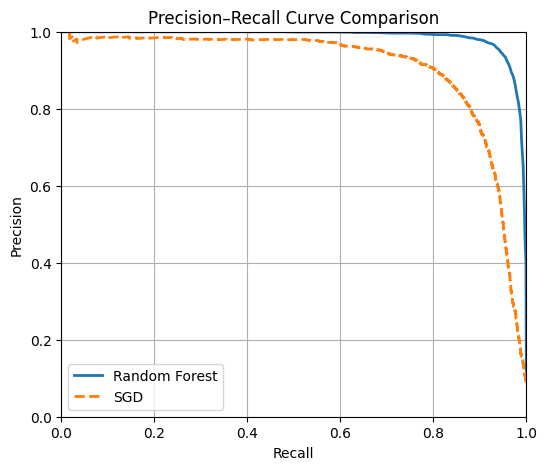

In [67]:
plt.figure(figsize=(6, 5))
plt.plot(
    recalls_forest,
    precisions_forest,
    linewidth=2,
    label="Random Forest"
)
plt.plot(
    recalls,
    precisions,
    linestyle="--",
    linewidth=2,
    label="SGD"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.axis([0, 1, 0, 1])
plt.grid(True)
plt.legend(loc="lower left")
plt.title("Precision–Recall Curve Comparison")
plt.savefig("pr_curve_comparison_plot.png", bbox_inches="tight")
plt.show()


In [71]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score, roc_auc_score, precision_score, recall_score
forest_clf = RandomForestClassifier(random_state=42)
y_probas_forest = cross_val_predict(
    forest_clf,
    X_train,
    y_train_5,
    cv=3,
    method="predict_proba"
)
y_scores_forest = y_probas_forest[:, 1]
y_pred_forest = y_scores_forest >= 0.5
metrics = {
    "F1 Score": f1_score(y_train_5, y_pred_forest),
    "ROC AUC": roc_auc_score(y_train_5, y_scores_forest),
    "Precision": precision_score(y_train_5, y_pred_forest),
    "Recall": recall_score(y_train_5, y_pred_forest),
}
for name, value in metrics.items():
    print(f"{name}: {value}")


F1 Score: 0.9120725750174459
ROC AUC: 0.9981587812164738
Precision: 0.9905267146646457
Recall: 0.8451341739411574


# Multiclass Classification

In [74]:
from sklearn.svm import SVC
import numpy as np
svm_clf = SVC(random_state=42)
svm_clf.fit(X_train[:2000], y_train[:2000])
digit_sample = some_digit.reshape(1, -1)
predicted_label = svm_clf.predict(digit_sample)
decision_scores = svm_clf.decision_function(digit_sample)
rounded_scores = np.round(decision_scores, 2)
print("Predicted label:", predicted_label)
print("Decision scores:", decision_scores)
print("Rounded scores:", rounded_scores)


Predicted label: [1]
Decision scores: [[-0.29432678  9.3037422   8.22733678  5.07436052  1.74243247  6.23052812
   3.8658019   2.7661489   7.25762516  0.72871566]]
Rounded scores: [[-0.29  9.3   8.23  5.07  1.74  6.23  3.87  2.77  7.26  0.73]]


In [78]:
import numpy as np
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
digit_sample = some_digit.reshape(1, -1)
svm_ovo = SVC(random_state=42, decision_function_shape="ovo")
svm_ovo.fit(X_train[:2000], y_train[:2000])

ovo_scores = svm_ovo.decision_function(digit_sample)
ovo_scores_rounded = np.round(ovo_scores, 2)

print("OVO decision scores:", ovo_scores_rounded)

svm_base = SVC(random_state=42)
ovr_clf = OneVsRestClassifier(svm_base)

ovr_clf.fit(X_train[:2000], y_train[:2000])

print("OvR classifier trained successfully")


OVO decision scores: [[-1.07 -1.08 -1.   -0.27 -1.46 -0.75 -0.44 -1.12 -0.34  1.1   1.05  1.21
   1.02  1.03  1.44  1.07  1.27  0.34  0.34  0.03  0.55  0.25  0.06  0.59
   0.43 -0.05  0.03  0.32 -0.64  0.58 -0.83 -0.28 -0.19 -0.53  0.14  0.3
   0.59 -0.62  0.68  0.21 -0.41  0.41 -0.33  0.16  0.89]]
OvR classifier trained successfully


In [92]:
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier

base_svm = SVC(random_state=42)
ovr_clf = OneVsRestClassifier(estimator=base_svm)
X_subset, y_subset = X_train[:2000], y_train[:2000]
ovr_clf.fit(X_subset, y_subset)
print("OvR classifier trained on subset")
print("Number of classifiers:", len(ovr_clf.estimators_))


OvR classifier trained on subset
Number of classifiers: 10


In [93]:
digit_sample = some_digit.reshape(1, -1)
ovr_prediction = ovr_clf.predict(digit_sample)
print("OvR prediction for the digit:", ovr_prediction)


OvR prediction for the digit: [1]


In [95]:
import numpy as np
from sklearn.linear_model import SGDClassifier

digit_sample = some_digit.reshape(1, -1)

num_ovr_estimators = len(ovr_clf.estimators_)
print("Number of OvR classifiers:", num_ovr_estimators)

sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train)

sgd_prediction = sgd_clf.predict(digit_sample)
print("SGD prediction:", sgd_prediction)

sgd_scores = np.round(sgd_clf.decision_function(digit_sample))
print("SGD decision scores (rounded):", sgd_scores)


Number of OvR classifiers: 10
SGD prediction: [1]
SGD decision scores (rounded): [[-72852.  35495. -11664. -12459. -32641. -16389. -28550. -68524.  -5067.
  -24901.]]


In [106]:
cross_val_score(sgd_clf, X_train, y_train, cv=3, scoring="accuracy")

array([0.88035714, 0.87214286, 0.87      ])

In [108]:
cross_val_score(
    sgd_clf,
    X_train_scaled[:5000],
    y_train[:5000],
    cv=3,
    scoring="accuracy"
)


array([0.88482304, 0.8830234 , 0.87815126])

# Error analysis

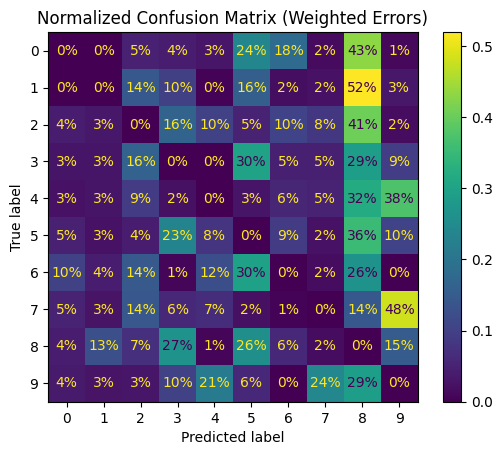

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay
sample_weight = (y_pred != y_35)

plt.rc('font', size=10)

ConfusionMatrixDisplay.from_predictions(
    y_35,
    y_pred,
    sample_weight=sample_weight,
    normalize="true",
    values_format=".0%"
)

plt.title("Normalized Confusion Matrix (Weighted Errors)")
plt.show()

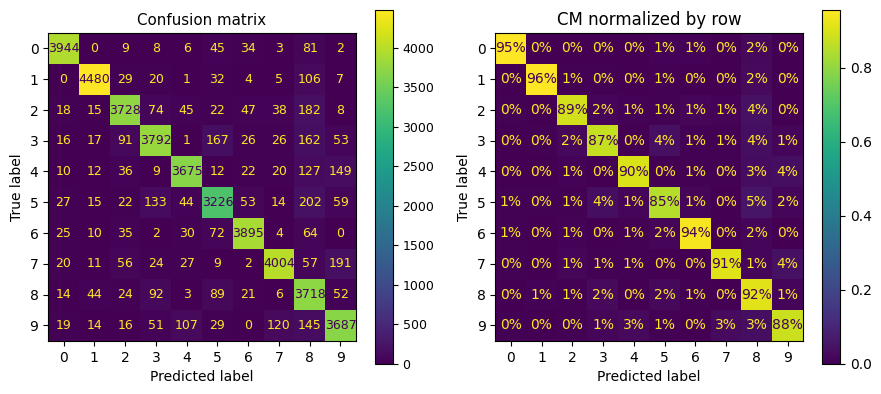

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(9, 4))
plt.rc('font', size=9)
ConfusionMatrixDisplay.from_predictions(
    y_35,
    y_pred,
    ax=axs[0]
)
axs[0].set_title("Confusion matrix")
plt.rc('font', size=10)
ConfusionMatrixDisplay.from_predictions(
    y_35,
    y_pred,
    ax=axs[1],
    normalize="true",
    values_format=".0%"
)
axs[1].set_title("CM normalized by row")

plt.tight_layout()
plt.show()


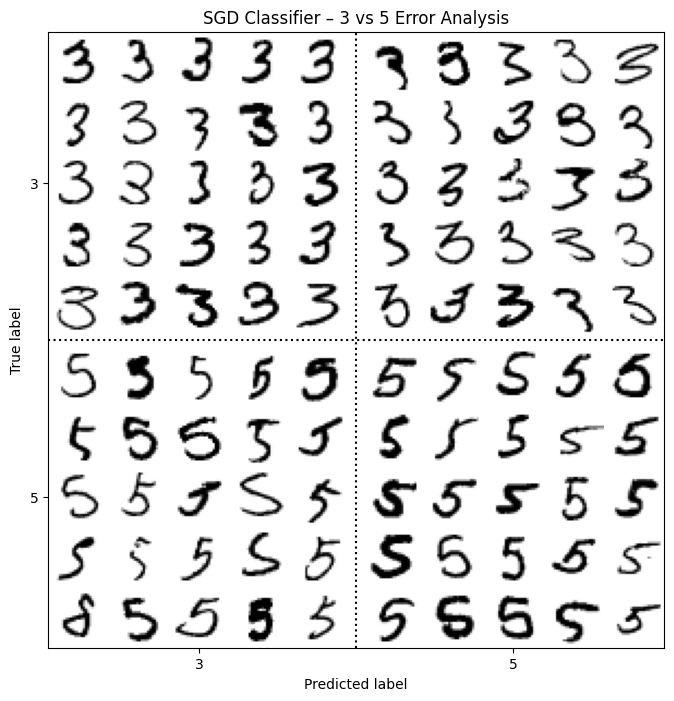

In [36]:
import warnings

from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

cl_a = 3
cl_b = 5

mask = (y == cl_a) | (y == cl_b)
X_35 = X[mask]
y_35 = y[mask]
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("sgd", SGDClassifier(
        random_state=42,
        max_iter=1000,
        tol=1e-3
    ))
])
y_pred = cross_val_predict(
    pipeline,
    X_35,
    y_35,
    cv=3,
    n_jobs=-1  
)

X_a = X_35[y_35 == cl_a]
X_b = X_35[y_35 == cl_b]

y_a_pred = y_pred[y_35 == cl_a]
y_b_pred = y_pred[y_35 == cl_b]

X_aa = X_a[y_a_pred == cl_a]  
X_ab = X_a[y_a_pred == cl_b]  
X_bb = X_b[y_b_pred == cl_b]  
X_ba = X_b[y_b_pred == cl_a]  
size = 5
pad = 0.2

plt.figure(figsize=(8, 8))

for images, (col, row) in [
    (X_ba, (0, 0)),  
    (X_bb, (1, 0)),  
    (X_aa, (0, 1)),  
    (X_ab, (1, 1)),  
]:
    for idx, image_data in enumerate(images[: size * size]):
        x = idx % size + col * (size + pad)
        y_ = idx // size + row * (size + pad)
        plt.imshow(
            image_data.reshape(28, 28),
            cmap="binary",
            extent=(x, x + 1, y_, y_ + 1),
        )

plt.xticks(
    [size / 2, size + pad + size / 2],
    [str(cl_a), str(cl_b)],
)
plt.yticks(
    [size / 2, size + pad + size / 2],
    [str(cl_b), str(cl_a)],
)

plt.plot([size + pad / 2, size + pad / 2], [0, 2 * size + pad], "k:")
plt.plot([0, 2 * size + pad], [size + pad / 2, size + pad / 2], "k:")

plt.axis([0, 2 * size + pad, 0, 2 * size + pad])
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("SGD Classifier – 3 vs 5 Error Analysis")
plt.show()


In [41]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

y_train_large = (y_train >= 7)
y_train_odd = (y_train % 2 == 1)
y_multilabel = np.c_[y_train_large, y_train_odd]
knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train, y_multilabel)


KNeighborsClassifier()

In [44]:
np.random.seed(42)
noise = np.random.randint(0, 100, (len(X_train), 784))
X_train_mod = X_train + noise
noise = np.random.randint(0, 100, (len(X_test), 784))
X_test_mod = X_test + noise
y_train_mod = X_train
y_test_mod = X_test

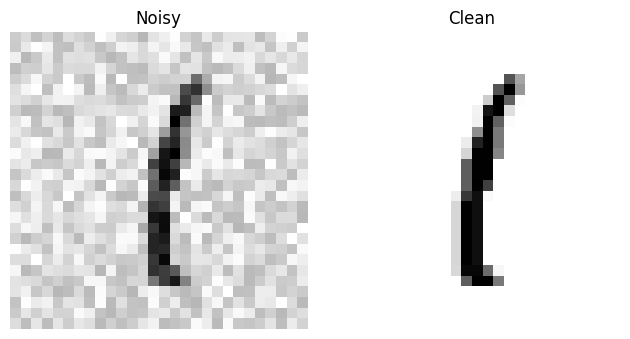

In [45]:
plt.subplot(121)
plot_digit(X_test_mod[0])
plt.title("Noisy")

plt.subplot(122)
plot_digit(y_test_mod[0])
plt.title("Clean")

plt.savefig("noisy_digit_example_plot.png", bbox_inches="tight")
plt.show()

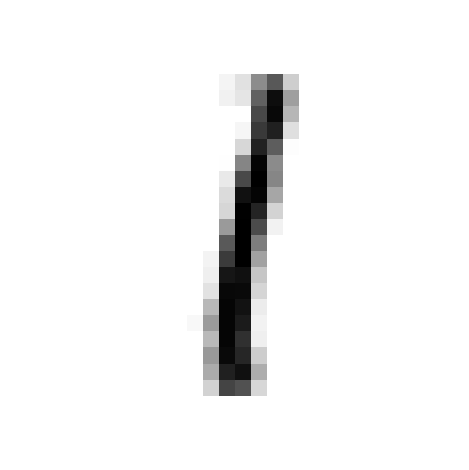

In [48]:
from sklearn.neighbors import KNeighborsRegressor
import matplotlib.pyplot as plt

knn_clf = KNeighborsRegressor(
    n_neighbors=5,
    weights="distance"
)

knn_clf.fit(X_train_mod, y_train_mod)

clean_digit = knn_clf.predict([X_test_mod[0]])

plot_digit(clean_digit[0])
plt.savefig("cleaned_digit_example_plot.png", bbox_inches="tight")
plt.show()


# Predction

In [52]:
import numpy as np
from scipy.ndimage import shift
import matplotlib.pyplot as plt

def shift_image(image, dx, dy):
    """
    Shift a 28x28 image by dx (x-axis) and dy (y-axis)
    """
    image = image.reshape(28, 28)
    shifted = shift(
        image,
        shift=(dy, dx),  
        mode="constant",
        cval=0
    )
    return shifted.reshape(-1)

image = X_train[1000] 

shifted_image_down = shift_image(image, 0, 5)
shifted_image_left = shift_image(image, -5, 0)

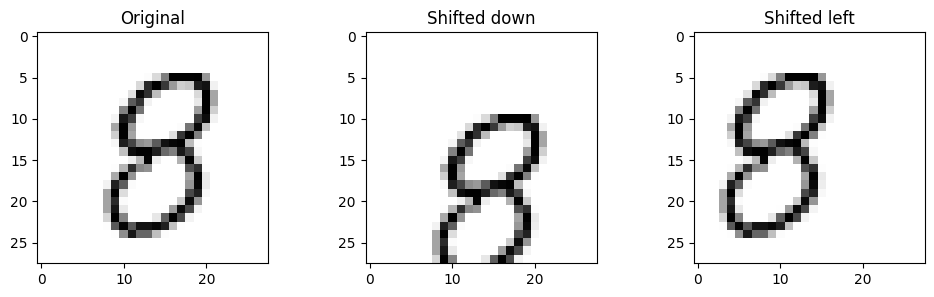

In [53]:
plt.figure(figsize=(12, 3))

plt.subplot(131)
plt.title("Original")
plt.imshow(image.reshape(28, 28), interpolation="nearest", cmap="Greys")

plt.subplot(132)
plt.title("Shifted down")
plt.imshow(shifted_image_down.reshape(28, 28), interpolation="nearest", cmap="Greys")

plt.subplot(133)
plt.title("Shifted left")
plt.imshow(shifted_image_left.reshape(28, 28), interpolation="nearest", cmap="Greys")

plt.show()


In [59]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from scipy.ndimage import shift

def shift_image(image, dx, dy):
    image = image.reshape(28, 28)
    shifted = shift(
        image,
        shift=(dy, dx),
        mode="constant",
        cval=0,
        order=0  
    )
    return shifted.reshape(-1)
X_train_augmented = []
y_train_augmented = []

for img, label in zip(X_train, y_train):
    X_train_augmented.append(img)
    y_train_augmented.append(label)

    X_train_augmented.append(shift_image(img, 1, 0))   
    y_train_augmented.append(label)

    X_train_augmented.append(shift_image(img, -1, 0))  
    y_train_augmented.append(label)

    X_train_augmented.append(shift_image(img, 0, 1))   
    y_train_augmented.append(label)

    X_train_augmented.append(shift_image(img, 0, -1))  
    y_train_augmented.append(label)

X_train_augmented = np.array(X_train_augmented)
y_train_augmented = np.array(y_train_augmented)
shuffle_idx = np.random.permutation(len(X_train_augmented))
X_train_augmented = X_train_augmented[shuffle_idx]
y_train_augmented = y_train_augmented[shuffle_idx]
knn_clf = KNeighborsClassifier(
    n_neighbors=4,
    weights="distance",
    n_jobs=-1
)

knn_clf.fit(X_train_augmented, y_train_augmented)
augmented_accuracy = knn_clf.score(X_test, y_test)
print("Augmented KNN accuracy:", augmented_accuracy)


Augmented KNN accuracy: 0.9754761904761905


## Conclusion and next steps

Compare the binary classifier metrics (precision, recall, F1, and ROC-AUC), review the multiclass confusion matrix, and inspect the digit-shift experiments. Record the actual metrics produced by a full run here before publishing; do not claim a model accuracy that has not been measured. The error-analysis cells focus on digits 3 and 5, while the full multiclass sections use all digit labels.